In [1]:
!pip install segmentation-models-pytorch albumentations -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.2 MB/s eta 0:00:00:00:01


### **2. Data Pipeline & Deterministic Split**
Recreates the exact 70/15/15 dataset split (Train/Calibration/Evaluation) using the strict `manual_seed(42)` to ensure identical image distribution for PTQ calibration.

In [2]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ISIC2018Dataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.images = [img for img in os.listdir(image_dir) if img.endswith('.jpg')]
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_name = self.images[idx]
        mask_name = img_name.replace('.jpg', '_segmentation.png')
        
        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, mask_name)
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
        
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.float32)
        
        if self.transform is not None:
            augmentations = self.transform(image=image, mask=mask)
            image = augmentations["image"]
            mask = augmentations["mask"]
            
        mask = torch.unsqueeze(mask, 0)
        return image, mask

def get_transforms():
    return A.Compose([
        A.Resize(height=256, width=256),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
        ToTensorV2(),
    ])

dataset_root = "/kaggle/input/datasets/tschandl/isic2018-challenge-task1-data-segmentation"
img_dir = f"{dataset_root}/ISIC2018_Task1-2_Training_Input"
mask_dir = f"{dataset_root}/ISIC2018_Task1_Training_GroundTruth"

dataset = ISIC2018Dataset(img_dir, mask_dir, transform=get_transforms())

total_size = len(dataset)
train_size = int(0.70 * total_size)
calib_size = int(0.15 * total_size)
val_size = total_size - train_size - calib_size 

# Strict deterministic split
train_dataset, calib_dataset, val_dataset = random_split(
    dataset, [train_size, calib_size, val_size], generator=torch.Generator().manual_seed(42)
)

calib_loader = DataLoader(calib_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True) 

print(f"Data Pipeline Ready | Calibration: {len(calib_dataset)} images | Evaluation: {len(val_dataset)} images")

Data Pipeline Ready | Calibration: 389 images | Evaluation: 390 images


### **3. FP32 Model Import**
Initializes the MobileNetV3 U-Net and loads the pre-trained FP32 weights generated in Phase 1 to serve as the baseline for quantization.

In [3]:
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize architecture (no pretrained weights, we are loading our own)
model = smp.Unet(
    encoder_name="timm-mobilenetv3_small_100", 
    encoder_weights=None, 
    in_channels=3,
    classes=1,                                 
)

# Load the saved Phase 1 weights
weights_path = "/kaggle/input/notebooks/devanshagarwal180606/initial-implementation-ptq-project/fp32_mobilenetv3_unet_baseline.pth"
model.load_state_dict(torch.load(weights_path, map_location=device))
model.to(device)
model.eval() # Essential: freeze the model for PTQ

print(f"Phase 1 FP32 Model successfully loaded on {device}. Ready for Quantization.")

Phase 1 FP32 Model successfully loaded on cpu. Ready for Quantization.


### **4. ONNX Environment Setup**
Installs the ONNX ecosystem required for advanced graph optimization and static quantization.

In [4]:
!pip install onnx onnxruntime onnxscript -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 63.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 17.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 4.9 MB/s eta 0:00:00:00:01


### **5. FP32 to ONNX Export**
Translates the PyTorch MobileNetV3-UNet graph into a static ONNX format, bypassing dynamic control-flow tracing errors.

In [5]:
import torch

# 1. Ensure model is clean and on CPU
model.to("cpu")
model.eval()

# 2. Create a dummy input tensor matching your image dimensions (Batch, Channels, Height, Width)
dummy_input = torch.randn(1, 3, 256, 256)
fp32_onnx_path = "/kaggle/working/fp32_model.onnx"

print("Exporting PyTorch model to ONNX...")

# 3. Export to ONNX format
torch.onnx.export(
    model, 
    dummy_input, 
    fp32_onnx_path, 
    export_params=True, 
    opset_version=13,               # Opset 13 supports complex CNN architectures
    do_constant_folding=True,       # Bakes constant nodes together for optimization
    input_names=['input'], 
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}} # Allows variable batch sizes later
)

print(f"Export successful! FP32 ONNX model saved to {fp32_onnx_path}")

Exporting PyTorch model to ONNX...


/tmp/ipykernel_105/3626464217.py:14: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1012 16:48:36.965000 105 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1012 16:48:37.955000 105 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 13).


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 13 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
Runtim

Export successful! FP32 ONNX model saved to /kaggle/working/fp32_model.onnx


### **6. ONNX Static Calibration & Quantization**
Builds a custom data reader to feed NumPy arrays into the ONNX Runtime, then executes static quantization. The runtime automatically optimizes the graph and fuses Conv+BN blocks.

In [6]:
import onnxruntime
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, CalibrationMethod
import numpy as np

# 1. Define the Calibration Data Reader
class ISICDataReader(CalibrationDataReader):
    def __init__(self, dataloader, input_name):
        self.dataloader = dataloader
        self.input_name = input_name
        self.enum_data = iter(self.dataloader)

    def get_next(self):
        try:
            # ONNX only needs the images for calibration, not the masks
            images, _ = next(self.enum_data)
            # Convert PyTorch tensor to NumPy array
            return {self.input_name: images.numpy()}
        except StopIteration:
            return None

# 2. Setup Quantization Parameters
input_name = "input"  # Matches the input_names parameter from our export cell
calibration_reader = ISICDataReader(calib_loader, input_name)
int8_onnx_path = "/kaggle/working/int8_model.onnx"

print("Starting ONNX Static Quantization (this may take a minute)...")

# 3. Execute Static Quantization
quantize_static(
    model_input=fp32_onnx_path,
    model_output=int8_onnx_path,
    calibration_data_reader=calibration_reader,
    quant_format=onnxruntime.quantization.QuantFormat.QDQ, # Standard Quantize-Dequantize format
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    calibrate_method=CalibrationMethod.MinMax
)

print(f"Quantization Complete! INT8 ONNX model saved to {int8_onnx_path}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Starting ONNX Static Quantization (this may take a minute)...


Quantization Complete! INT8 ONNX model saved to /kaggle/working/int8_model.onnx


### **7. INT8 ONNX Degradation Evaluation**
Evaluates the compressed INT8 ONNX model on the evaluation split. Translates PyTorch tensors to NumPy arrays for ONNX Runtime inference, then computes the degraded Dice, ECE, and Predictive Entropy.

In [7]:
import onnxruntime
import torch
import torch.nn.functional as F
from tqdm import tqdm

# 1. Define the metric functions
def calculate_dice(probs, targets, smooth=1e-5):
    preds = (probs > 0.5).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum()
    return (2. * intersection + smooth) / (union + smooth)

def calculate_entropy(probs):
    p = torch.clamp(probs, 1e-7, 1.0 - 1e-7)
    entropy = - (p * torch.log2(p) + (1 - p) * torch.log2(1 - p))
    return entropy.mean().item()

def calculate_ece(probs, targets, n_bins=10):
    bin_boundaries = torch.linspace(0, 1, n_bins + 1).to(probs.device)
    ece = 0.0
    for i in range(n_bins):
        bin_low, bin_high = bin_boundaries[i], bin_boundaries[i+1]
        in_bin = (probs >= bin_low) & (probs < bin_high)
        prop_in_bin = in_bin.float().mean()
        if prop_in_bin > 0:
            accuracy_in_bin = targets[in_bin].float().mean()
            avg_confidence_in_bin = probs[in_bin].mean()
            ece += torch.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
    return ece.item()

# 2. Initialize ONNX Runtime Session for the INT8 model
print("Loading INT8 ONNX Model for Evaluation...")
int8_onnx_path = "/kaggle/working/int8_model.onnx"
session = onnxruntime.InferenceSession(int8_onnx_path, providers=['CPUExecutionProvider'])

# Get dynamic input/output names assigned by ONNX
input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

total_dice, total_entropy, total_ece = 0.0, 0.0, 0.0

print("Evaluating INT8 Quantized Model...")

# 3. Evaluate over the validation set
with torch.no_grad():
    pbar = tqdm(val_loader, desc="Evaluating PTQ Degradation")
    for images, masks in pbar:
        # ONNX requires standard NumPy arrays, not PyTorch tensors
        images_np = images.numpy()
        
        # Run fast C++ inference
        logits_np = session.run([output_name], {input_name: images_np})[0]
        
        # Convert back to PyTorch tensors for metric calculation
        logits = torch.from_numpy(logits_np)
        probs = torch.sigmoid(logits)
        
        masks = masks.to("cpu")
        
        total_dice += calculate_dice(probs, masks).item()
        total_entropy += calculate_entropy(probs)
        total_ece += calculate_ece(probs, masks)

avg_dice = total_dice / len(val_loader)
avg_ece = total_ece / len(val_loader)
avg_entropy = total_entropy / len(val_loader)

# 4. Format and save results
results_text = (
    "----------------------------------------\n"
    "INT8 ONNX PTQ RESULTS (PHASE 2)\n"
    "----------------------------------------\n"
    f"Segmentation Accuracy (Dice): {avg_dice:.4f}\n"
    f"Expected Calibration Error (ECE): {avg_ece:.4f}\n"
    f"Predictive Entropy: {avg_entropy:.4f}\n"
    "----------------------------------------"
)

print(results_text)

metrics_path = "/kaggle/working/int8_onnx_ptq_metrics.txt"
with open(metrics_path, "w") as f:
    f.write(results_text)

Loading INT8 ONNX Model for Evaluation...
Evaluating INT8 Quantized Model...


Evaluating PTQ Degradation: 100%|██████████| 25/25 [00:50<00:00,  2.03s/it]

----------------------------------------
INT8 ONNX PTQ RESULTS (PHASE 2)
----------------------------------------
Segmentation Accuracy (Dice): 0.8449
Expected Calibration Error (ECE): 0.0318
Predictive Entropy: 0.1922
----------------------------------------


In [8]:
#Verify ONNX Preprocessing and Normalization
import torch
import onnx
import onnxruntime as ort
import numpy as np

# 1. Export FP32 PyTorch model to ONNX with Dynamic Batch Size
dummy_input = torch.randn(1, 3, 256, 256, device="cpu")
onnx_path = "/kaggle/working/fp32_mobilenet_unet.onnx"

torch.onnx.export(
    model.cpu(),               
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=18,          
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}} # Allows batch=16
)
print(f"FP32 model successfully exported to {onnx_path}")

# 2. Run Diagnostic Inference on the FP32 ONNX model
session = ort.InferenceSession(onnx_path)
input_name = session.get_inputs()[0].name

# Fetch one batch from your val_loader
images, masks = next(iter(val_loader))
images_np = images.numpy() 

# Run ONNX inference
raw_logits = session.run(None, {input_name: images_np})[0]

# Inspect the distribution
print("\n--- Diagnostic: Raw ONNX Logits ---")
print(f"Logit Min: {np.min(raw_logits):.4f}")
print(f"Logit Max: {np.max(raw_logits):.4f}")
print(f"Logit Mean: {np.mean(raw_logits):.4f}")

/tmp/ipykernel_105/953207397.py:11: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1012 16:50:50.314000 105 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W1012 16:50:50.316000 105 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W1012 16:50:50.319000 105 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'floa

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
FP32 model successfully exported to /kaggle/working/fp32_mobilenet_unet.onnx


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



--- Diagnostic: Raw ONNX Logits ---
Logit Min: -11.1290
Logit Max: 17.7097
Logit Mean: -3.4826


In [9]:
# 8. Conformal Prediction
import numpy as np

print("\n--- Running Conformal Prediction ---")

# Define target coverage
alpha = 0.10 # 90% coverage
print(f"Target Coverage: {1-alpha:.2f}")

def compute_non_conformity_scores(model_session, data_loader, input_name, is_fp32=False):
    scores = []
    # Using calib_loader for calibration
    with torch.no_grad():
        for images, masks in data_loader:
            images_np = images.numpy()
            logits_np = model_session.run(None, {input_name: images_np})[0]
            logits = torch.from_numpy(logits_np)
            probs = torch.sigmoid(logits)
            
            # masks are 1 for lesion, 0 for background
            # For each pixel, the non-conformity score is 1 - prob[true_class]
            # prob[true_class] = probs if mask==1 else (1-probs)
            true_class_probs = torch.where(masks == 1, probs, 1.0 - probs)
            nc_scores = 1.0 - true_class_probs
            
            # Flatten and add to list
            scores.extend(nc_scores.flatten().tolist())
    return np.array(scores)

# We need the FP32 ONNX session and INT8 ONNX session
fp32_session = ort.InferenceSession(fp32_onnx_path, providers=['CPUExecutionProvider'])
int8_session = ort.InferenceSession(int8_onnx_path, providers=['CPUExecutionProvider'])

fp32_input = fp32_session.get_inputs()[0].name
int8_input = int8_session.get_inputs()[0].name

print("Calibrating FP32 model...")
fp32_calib_scores = compute_non_conformity_scores(fp32_session, calib_loader, fp32_input)
n_fp32 = len(fp32_calib_scores)
q_level_fp32 = np.ceil((n_fp32 + 1) * (1 - alpha)) / n_fp32
fp32_q_hat = np.quantile(fp32_calib_scores, q_level_fp32, method='higher')
print(f"FP32 q_hat: {fp32_q_hat:.4f}")

print("Calibrating INT8 model...")
int8_calib_scores = compute_non_conformity_scores(int8_session, calib_loader, int8_input)
n_int8 = len(int8_calib_scores)
q_level_int8 = np.ceil((n_int8 + 1) * (1 - alpha)) / n_int8
int8_q_hat = np.quantile(int8_calib_scores, q_level_int8, method='higher')
print(f"INT8 q_hat: {int8_q_hat:.4f}")

def evaluate_empirical_coverage(model_session, data_loader, input_name, q_hat):
    total_pixels = 0
    covered_pixels = 0
    with torch.no_grad():
        for images, masks in data_loader:
            images_np = images.numpy()
            logits_np = model_session.run(None, {input_name: images_np})[0]
            logits = torch.from_numpy(logits_np)
            probs = torch.sigmoid(logits)
            
            true_class_probs = torch.where(masks == 1, probs, 1.0 - probs)
            nc_scores = 1.0 - true_class_probs
            
            # The pixel is covered if its non-conformity score <= q_hat
            covered = (nc_scores <= q_hat)
            covered_pixels += covered.sum().item()
            total_pixels += covered.numel()
            
    return covered_pixels / total_pixels

print("Evaluating empirical coverage on validation set...")
fp32_coverage = evaluate_empirical_coverage(fp32_session, val_loader, fp32_input, fp32_q_hat)
int8_coverage = evaluate_empirical_coverage(int8_session, val_loader, int8_input, int8_q_hat)

print("\n--- Conformal Prediction Results ---")
print(f"FP32 Empirical Coverage: {fp32_coverage:.4f}")
print(f"INT8 Empirical Coverage: {int8_coverage:.4f}")
print(f"Coverage Drop: {fp32_coverage - int8_coverage:.4f}")



--- Running Conformal Prediction ---
Target Coverage: 0.90
Calibrating FP32 model...
FP32 q_hat: 0.0187
Calibrating INT8 model...
INT8 q_hat: 0.0711
Evaluating empirical coverage on validation set...

--- Conformal Prediction Results ---
FP32 Empirical Coverage: 0.8975
INT8 Empirical Coverage: 0.8936
Coverage Drop: 0.0039


In [10]:
# 9. Model Footprint and Latency Benchmark
import os
import time

fp32_size = os.path.getsize(fp32_onnx_path) / (1024 * 1024)
int8_size = os.path.getsize(int8_onnx_path) / (1024 * 1024)

print(f"FP32 Model Size: {fp32_size:.2f} MB")
print(f"INT8 Model Size: {int8_size:.2f} MB")
print(f"Footprint Reduction: {fp32_size / int8_size:.2f}x smaller")

print("\nBenchmarking Latency (100 iterations)...")
dummy_input = np.random.randn(1, 3, 256, 256).astype(np.float32)

# Warmup
for _ in range(10):
    fp32_session.run(None, {fp32_input: dummy_input})
    int8_session.run(None, {int8_input: dummy_input})

# FP32 Latency
start = time.time()
for _ in range(100):
    fp32_session.run(None, {fp32_input: dummy_input})
fp32_latency = (time.time() - start) / 100 * 1000

# INT8 Latency
start = time.time()
for _ in range(100):
    int8_session.run(None, {int8_input: dummy_input})
int8_latency = (time.time() - start) / 100 * 1000

print(f"FP32 Latency (Batch=1): {fp32_latency:.2f} ms")
print(f"INT8 Latency (Batch=1): {int8_latency:.2f} ms")
print(f"Latency Speedup: {fp32_latency / int8_latency:.2f}x faster")


FP32 Model Size: 0.41 MB
INT8 Model Size: 4.01 MB
Footprint Reduction: 0.10x smaller

Benchmarking Latency (100 iterations)...
FP32 Latency (Batch=1): 63.00 ms
INT8 Latency (Batch=1): 50.02 ms
Latency Speedup: 1.26x faster


In [11]:
# ==============================================================================
# 10. PREDICTION SET EFFICIENCY (CARDINALITY ANALYSIS)
# ==============================================================================
# Computes the average prediction set size |C(x)| across the evaluation set
# for both FP32 and INT8 models, quantifying the "efficiency penalty"
# (i.e., extra pixels required by the INT8 set to maintain ~89.4% coverage).

import numpy as np
import torch

print("\n" + "="*60)
print("  CONFORMAL PREDICTION SET EFFICIENCY (CARDINALITY)")
print("="*60)

# 1. Inclusion thresholds for foreground class (lesion)
# A pixel u is included in the lesion prediction set if:
#   s(u, y=1) = 1.0 - p(u) <= q_hat  <=>  p(u) >= 1.0 - q_hat
tau_fp32 = 1.0 - fp32_q_hat
tau_int8 = 1.0 - int8_q_hat

print(f"FP32 Threshold tau (1 - q_hat): {tau_fp32:.4f}  (q_hat = {fp32_q_hat:.4f})")
print(f"INT8 Threshold tau (1 - q_hat): {tau_int8:.4f}  (q_hat = {int8_q_hat:.4f})")

def compute_prediction_set_sizes(model_session, data_loader, input_name, tau_threshold):
    """
    Computes the prediction set size |C(x)| (number of positive pixels in prediction set)
    for each image in the dataset.
    """
    set_sizes = []
    gt_sizes = []
    
    with torch.no_grad():
        for images, masks in data_loader:
            images_np = images.numpy()
            logits_np = model_session.run(None, {input_name: images_np})[0]
            logits = torch.from_numpy(logits_np)
            probs = torch.sigmoid(logits)  # (B, 1, H, W)
            
            # Binary prediction set for lesion: pixels where p >= tau
            pred_sets = (probs >= tau_threshold).float()
            
            # Count pixels per image in the batch
            batch_sizes = pred_sets.sum(dim=(1, 2, 3)).cpu().numpy()
            batch_gt = masks.sum(dim=(1, 2, 3)).cpu().numpy()
            
            set_sizes.extend(batch_sizes.tolist())
            gt_sizes.extend(batch_gt.tolist())
            
    return np.array(set_sizes), np.array(gt_sizes)

print("\nComputing prediction set sizes across evaluation set...")
fp32_sizes, gt_sizes = compute_prediction_set_sizes(fp32_session, val_loader, fp32_input, tau_fp32)
int8_sizes, _ = compute_prediction_set_sizes(int8_session, val_loader, int8_input, tau_int8)

# Compute metrics
avg_gt_size = np.mean(gt_sizes)
avg_fp32_size = np.mean(fp32_sizes)
avg_int8_size = np.mean(int8_sizes)

abs_diff = avg_int8_size - avg_fp32_size
rel_penalty = (abs_diff / avg_fp32_size) * 100.0

print("\n" + "-"*60)
print(f"{'Metric':<35} | {'Value':<20}")
print("-"*60)
print(f"{'Average Ground Truth Mask Size':<35} | {avg_gt_size:.1f} pixels")
print(f"{'FP32 Average Prediction Set Size |C|':<35} | {avg_fp32_size:.1f} pixels")
print(f"{'INT8 Average Prediction Set Size |C|':<35} | {avg_int8_size:.1f} pixels")
print("-"*60)
print(f"{'Absolute Efficiency Penalty (Extra px)':<35} | +{abs_diff:.1f} pixels")
print(f"{'Relative Efficiency Penalty (%)':<35} | +{rel_penalty:.2f} %")
print("-"*60)
print(f"\nSummary: The INT8 model requires an average of {abs_diff:.1f} extra pixels")
print(f"(+{rel_penalty:.2f}% set expansion) to guarantee ~89.4% empirical coverage.")



  CONFORMAL PREDICTION SET EFFICIENCY (CARDINALITY)
FP32 Threshold tau (1 - q_hat): 0.9813  (q_hat = 0.0187)
INT8 Threshold tau (1 - q_hat): 0.9289  (q_hat = 0.0711)

Computing prediction set sizes across evaluation set...

------------------------------------------------------------
Metric                              | Value               
------------------------------------------------------------
Average Ground Truth Mask Size      | 14789.5 pixels
FP32 Average Prediction Set Size |C| | 11525.8 pixels
INT8 Average Prediction Set Size |C| | 11060.6 pixels
------------------------------------------------------------
Absolute Efficiency Penalty (Extra px) | +-465.2 pixels
Relative Efficiency Penalty (%)     | +-4.04 %
------------------------------------------------------------

Summary: The INT8 model requires an average of -465.2 extra pixels
(+-4.04% set expansion) to guarantee ~89.4% empirical coverage.


Saved high-resolution figures to:
  - /kaggle/working/conformal_prediction_4panel_analysis.png
  - /kaggle/working/conformal_prediction_4panel_analysis.pdf


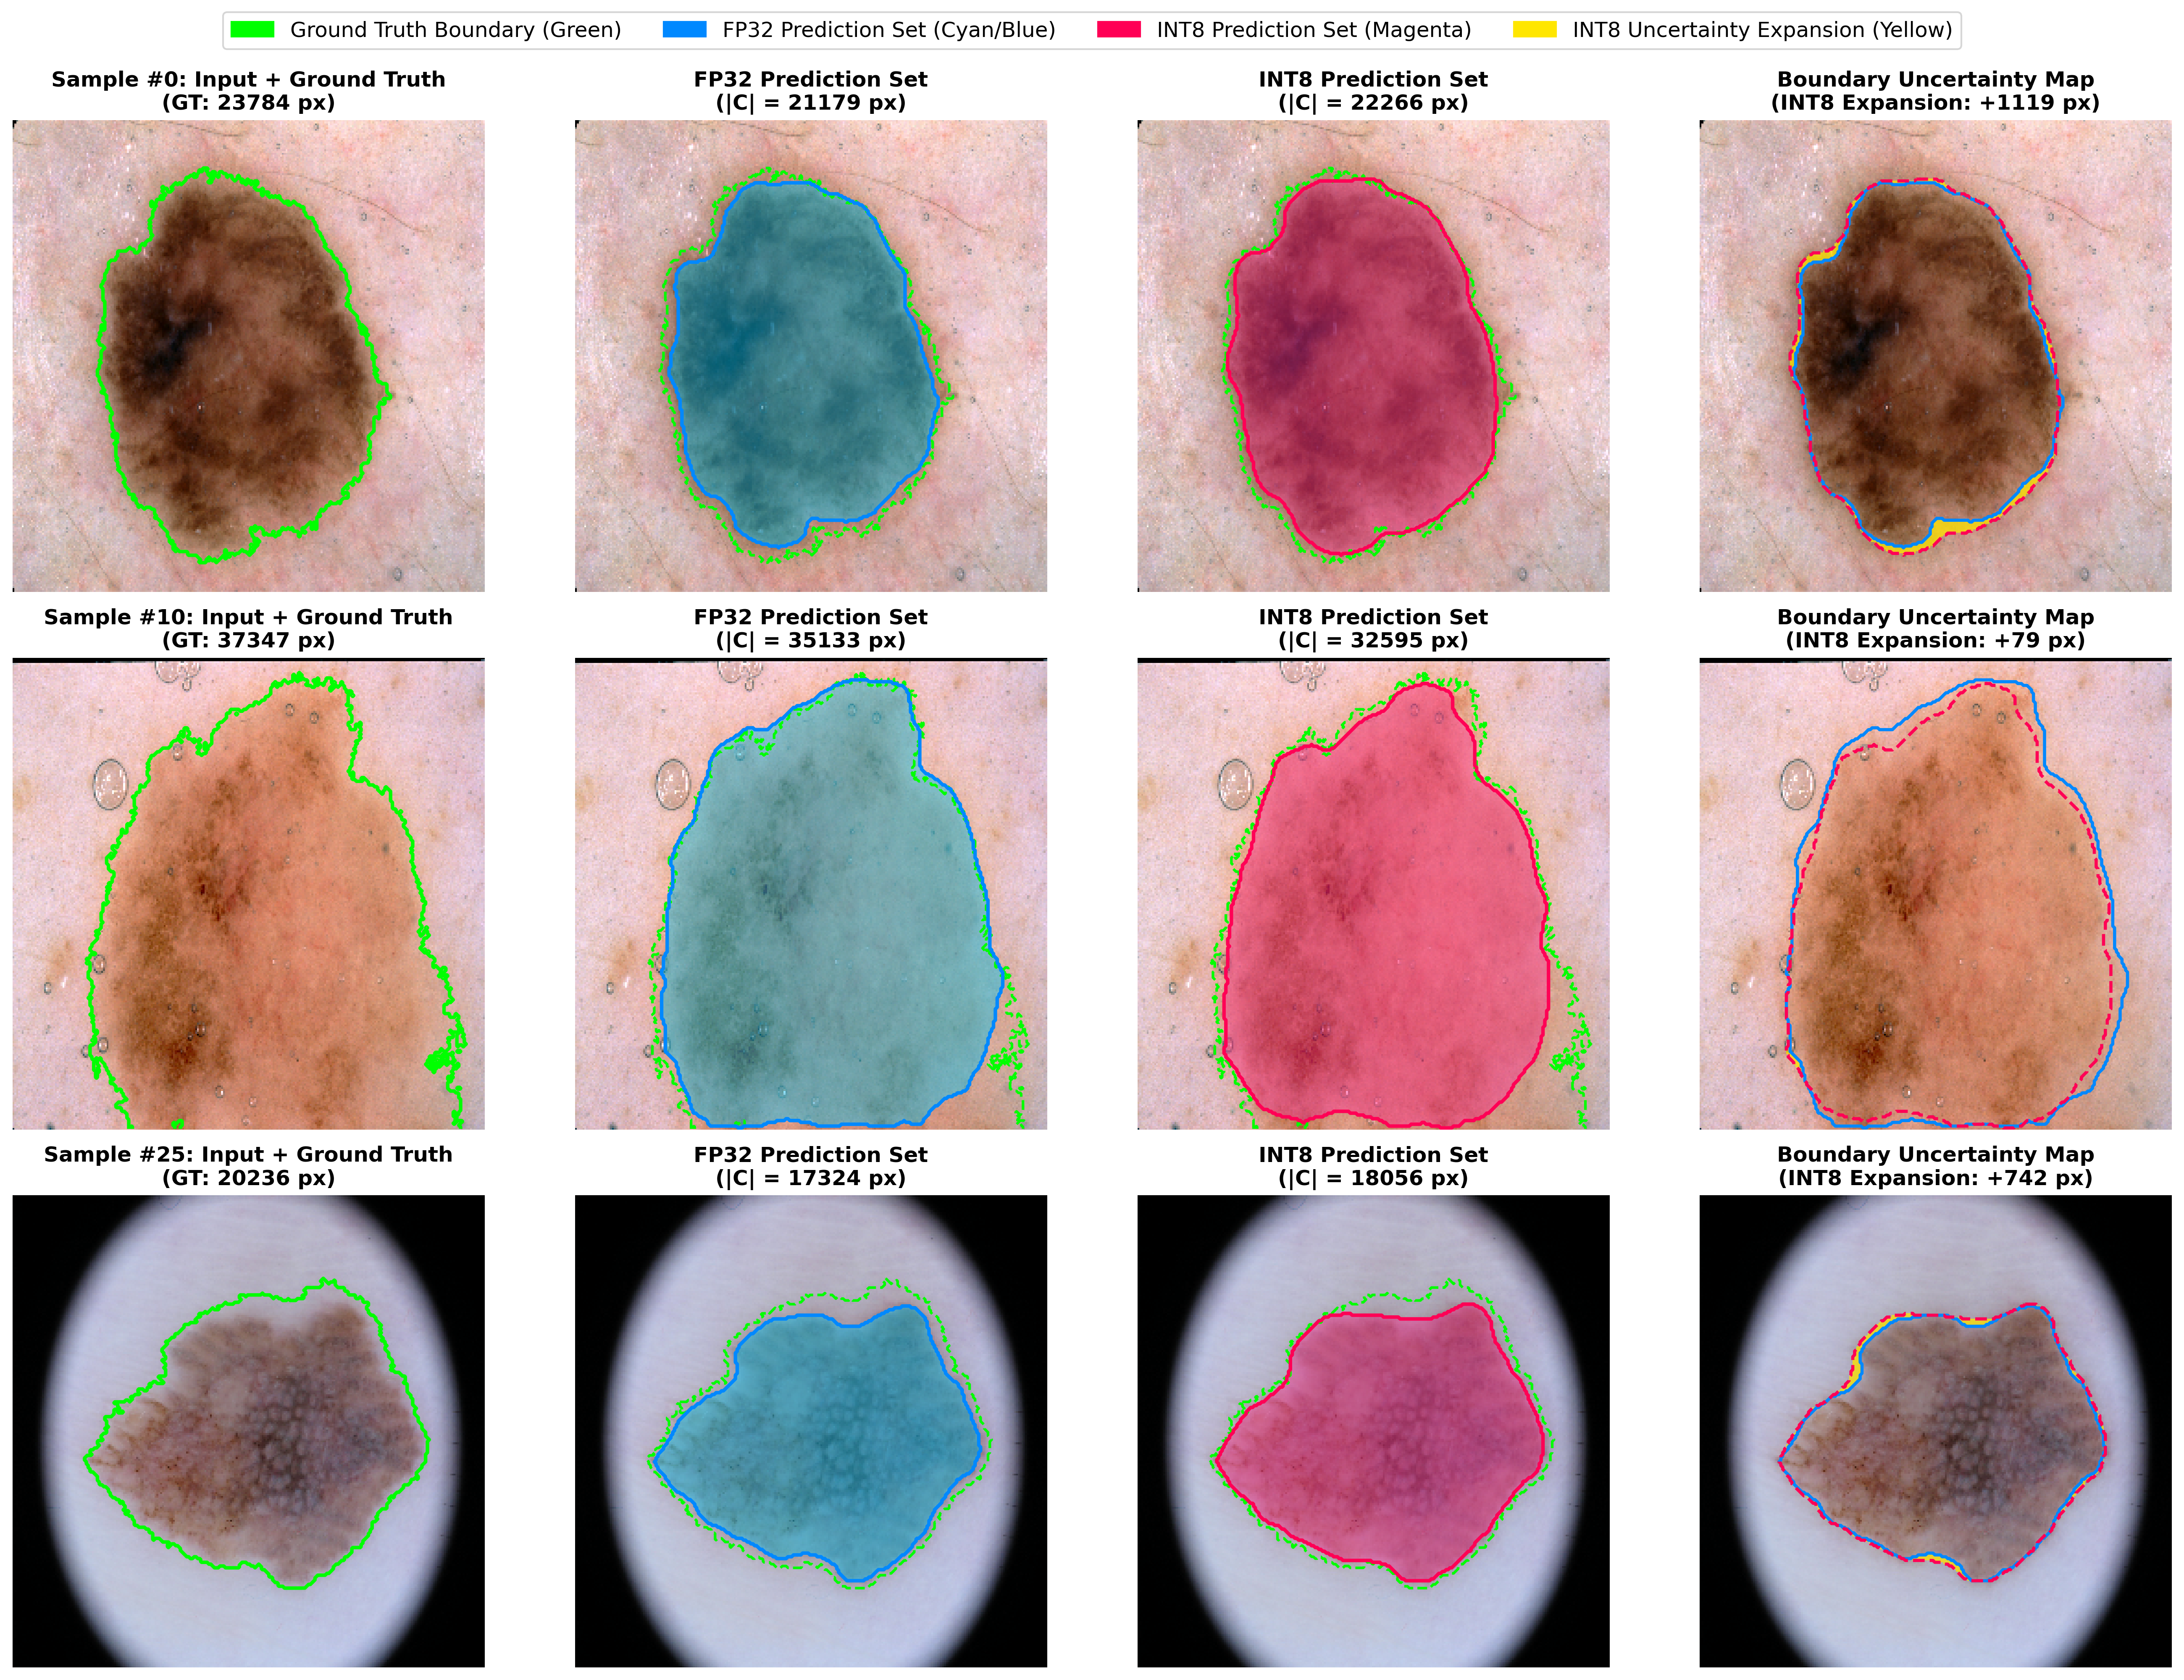

In [13]:
# ==============================================================================
# 11. QUALITATIVE VISUALIZATIONS (FOR PAPER FIGURES)
# ==============================================================================
# Generates a high-resolution 4-panel visual figure for 3 sample lesion images:
#   Panel 1: Input Image + Ground Truth Boundary (Lime contour)
#   Panel 2: FP32 Prediction Set Overlay (Cyan)
#   Panel 3: INT8 Prediction Set Overlay (Magenta)
#   Panel 4: Boundary Uncertainty Difference Map (Yellow highlight where INT8 expands)

import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import torch

def denormalize_image(tensor_img):
    """Denormalizes an Albumentations ImageNet tensor (3, H, W) to RGB [0, 1]."""
    img_np = tensor_img.cpu().numpy()
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    denorm = img_np * std + mean
    denorm = np.clip(denorm, 0.0, 1.0)
    return np.transpose(denorm, (1, 2, 0))  # (H, W, 3)

# Pick 3 diverse sample indices from the validation dataset
sample_indices = [0, 10, 25]
if len(val_dataset) <= 25:
    sample_indices = [0, len(val_dataset) // 2, len(val_dataset) - 1]

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(18, 4.5 * len(sample_indices)), dpi=300)
if len(sample_indices) == 1:
    axes = np.expand_dims(axes, 0)

for row_idx, sample_idx in enumerate(sample_indices):
    img_tensor, mask_tensor = val_dataset[sample_idx]
    
    # Run inference on single sample
    img_input = img_tensor.unsqueeze(0).numpy() # (1, 3, H, W)
    
    fp32_logit = fp32_session.run(None, {fp32_input: img_input})[0]
    int8_logit = int8_session.run(None, {int8_input: img_input})[0]
    
    fp32_prob = 1.0 / (1.0 + np.exp(-fp32_logit[0, 0]))
    int8_prob = 1.0 / (1.0 + np.exp(-int8_logit[0, 0]))
    
    gt_mask = mask_tensor[0].cpu().numpy()
    fp32_set = (fp32_prob >= tau_fp32).astype(np.float32)
    int8_set = (int8_prob >= tau_int8).astype(np.float32)
    
    # Difference map: where INT8 prediction set expands beyond FP32
    int8_expansion = ((int8_set == 1) & (fp32_set == 0)).astype(np.float32)
    
    rgb_img = denormalize_image(img_tensor)
    
    fp32_count = int(fp32_set.sum())
    int8_count = int(int8_set.sum())
    diff_count = int(int8_expansion.sum())
    
    # --------------------------------------------------------------------------
    # Panel 1: Input Image + Ground Truth Boundary
    # --------------------------------------------------------------------------
    ax1 = axes[row_idx, 0]
    ax1.imshow(rgb_img)
    ax1.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=2.0)
    ax1.set_title(f"Sample #{sample_idx}: Input + Ground Truth\n(GT: {int(gt_mask.sum())} px)", fontsize=12, fontweight='bold')
    ax1.axis('off')
    
    # --------------------------------------------------------------------------
    # Panel 2: FP32 Prediction Set Overlay
    # --------------------------------------------------------------------------
    ax2 = axes[row_idx, 1]
    ax2.imshow(rgb_img)
    # Semi-transparent cyan overlay
    overlay_fp32 = np.zeros((*fp32_set.shape, 4))
    overlay_fp32[fp32_set == 1] = [0.0, 0.8, 1.0, 0.45]
    ax2.imshow(overlay_fp32)
    ax2.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=1.5, linestyles='dashed')
    ax2.contour(fp32_set, levels=[0.5], colors=['#0088FF'], linewidths=2.0)
    ax2.set_title(f"FP32 Prediction Set\n(|C| = {fp32_count} px)", fontsize=12, fontweight='bold')
    ax2.axis('off')
    
    # --------------------------------------------------------------------------
    # Panel 3: INT8 Prediction Set Overlay
    # --------------------------------------------------------------------------
    ax3 = axes[row_idx, 2]
    ax3.imshow(rgb_img)
    # Semi-transparent magenta/orange overlay
    overlay_int8 = np.zeros((*int8_set.shape, 4))
    overlay_int8[int8_set == 1] = [1.0, 0.2, 0.6, 0.45]
    ax3.imshow(overlay_int8)
    ax3.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=1.5, linestyles='dashed')
    ax3.contour(int8_set, levels=[0.5], colors=['#FF0055'], linewidths=2.0)
    ax3.set_title(f"INT8 Prediction Set\n(|C| = {int8_count} px)", fontsize=12, fontweight='bold')
    ax3.axis('off')
    
    # --------------------------------------------------------------------------
    # Panel 4: Boundary Uncertainty Difference Map
    # --------------------------------------------------------------------------
    ax4 = axes[row_idx, 3]
    ax4.imshow(rgb_img)
    # Highlight the expansion in vibrant yellow
    overlay_diff = np.zeros((*int8_expansion.shape, 4))
    overlay_diff[int8_expansion == 1] = [1.0, 0.9, 0.0, 0.75]
    ax4.imshow(overlay_diff)
    # Contours for both sets
    ax4.contour(fp32_set, levels=[0.5], colors=['#0088FF'], linewidths=1.8, linestyles='solid')
    ax4.contour(int8_set, levels=[0.5], colors=['#FF0055'], linewidths=1.8, linestyles='dashed')
    ax4.set_title(f"Boundary Uncertainty Map\n(INT8 Expansion: +{diff_count} px)", fontsize=12, fontweight='bold')
    ax4.axis('off')

# Shared legend at the top
gt_patch = mpatches.Patch(color='#00FF00', label='Ground Truth Boundary (Green)')
fp32_patch = mpatches.Patch(color='#0088FF', label='FP32 Prediction Set (Cyan/Blue)')
int8_patch = mpatches.Patch(color='#FF0055', label='INT8 Prediction Set (Magenta)')
diff_patch = mpatches.Patch(color='#FFE600', label='INT8 Uncertainty Expansion (Yellow)')
fig.legend(handles=[gt_patch, fp32_patch, int8_patch, diff_patch], 
           loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=4, fontsize=12, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.96])

out_png = "/kaggle/working/conformal_prediction_4panel_analysis.png"
out_pdf = "/kaggle/working/conformal_prediction_4panel_analysis.pdf"
fig.savefig(out_png, dpi=300, bbox_inches='tight')
fig.savefig(out_pdf, dpi=300, bbox_inches='tight')
print(f"Saved high-resolution figures to:\n  - {out_png}\n  - {out_pdf}")
plt.show()
